<a href="https://colab.research.google.com/github/BB-lab24/autoencoder-next-digit/blob/main/Autoencoder-Next-Digit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Autoencoder for Next Digit Creation

#

### **Purpose**
***
#

This particular project is about implementing an autoencoder in order to solve the next digit creation problem, utilizing the MNIST dataset. By using back propagation, the neural network takes as an input the image of a number n ∈ {0,1,...,9} and returns as an output the image of the digit that follows. We try out different architectures for the network and we evaluate it's performance based on the reconstruction's quality (MSE), and the ability to recognize the output through an independent classifier. Lastly, a comparison also takes place using the PCA method. Everything regarding the coding part is written in Pytorch. As for the hardware, we make use of the CPU or Google Colab's T4 GPU, depending on availability, so the running times may vary in each attempt.
#



### **Chosen Dataset**
***
#

The dataset used for this project is the MNIST dataset, which is a classic for handwritten digits recognition. It consists of 70.000 images (60.000 training + 10.000 test), where the dimensions of each picture is 28x28 pixels (grayscale), and all of them can be categorized into 10 classes (~ 7.000 each), from digit 0 to digit 9. The data are separated in three sets: training set (60%), validation set (20%) and test set (20%). Shuffling is also used before the separation in order to avoid bias.
#


### **About the Autoencoder**
***
#

An autoencoder consists mainly of the following parts:

*  **Encoder**: This fisrt part includes the input layer and one or more hidden layers. It extracts features and keeps the most critical information.

*  **Latent space**: It is a hidden layer that contains the compressed representation of the data. We change the number of it's neurons to get different architectures. It connects the encoder and the decoder.

*  **Decoder**: This is the last part that takes the compressed data and expands them to their original size.

#


### **Project's Layout**
***
#

The project is mainly structured in the following order (sections):

1. Imported modules' description
2. Device configuration, preparing and loading the data
3. Networks architecture
4. Autoencoder training
5. Digit classifier training
6. Evaluating performance
7. Comparison with PCA
8. Visualization
9. Main execution

## **1\. Imported Modules' Description**
***
#

The modules we use throughout the project are the following:

*  ***torch*** : The library that provides tensors (multi-dimensional arrays) and fundamental operations for deep learning.

*   ***torch.nn(as nn)*** : Contains building blocks for neural networks: layers, activation functions, loss functions, and the base nn.Module class.

*   ***torch.optim(as optim)*** : Provides optimization algorithms for training. Implements back-propagation algorithms to update network weights.

*   ***Dataloader*** : Loads data in batches, handles shuffling, and provides parallel processing. Facilitates iteration over training/test data efficiently.

*   ***TensorDataset*** : A simple PyTorch wrapper that pairs multiple tensors (features and labels) into a single dataset.

*  ***random_split*** : It randomly partitions our dataset into non-overlapping sub-datasets of specified lengths. We use it to create training, validation, and testing sets while ensuring the data is shuffled.

*   ***torchvision*** : Library for Computer Vision tasks. Contains ready-to-use datasets (like CIFAR-10 in this case), pre-trained models, and utility functions for image processing.

*   ***torchvision.transforms(as transforms)*** : Image preprocessing and augmentation tools. Includes operations like normalization, resizing, cropping, flipping, and conversion to tensors.

*  ***numpy*** : More precisely a library used for working with arrays which are way faster to process than lists. We treat the train and test data as arrays.

*   ***matplotlib.pyplot(as plt)*** : Plotting library for creating visualizations. Used to generate graphs, charts, and display images (loss curves, accuracy plots).

*   ***PCA(from sklearn.decomposition)*** : A dimensionality reduction technique that transforms data into a lower-dimensional space by finding the directions (principal components) of maximum variance.

*  ***KFold(from sklearn.model_selection)*** : It provides a cross-validation strategy that splits a dataset into k consecutive folds (subsets). Each fold is used once as a validation set while the remaining k-1 folds form the training set

*  ***time*** : We use certain functions of this module in order to measure the training and pediction time of each method.

* ***defaultdict(from collections)*** : A dictionary subclass that calls a function to provide a default value for a nonexistent key, preventing KeyError exceptions.

*  ***seaborn(as sns)*** : A statistical data visualization library built on top of Matplotlib that provides a high-level interface for attractive, informative graphics.



The related code follows:


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, random_split
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.model_selection import KFold
import time
from collections import defaultdict
import seaborn as sns

## **2\. Device Configuration, Preparing and Loading the Data**
***
#

In this sextion the following take place:

*  **Device Selection**: Automatically selects GPU (CUDA) if available, otherwise falls back to CPU. This ensures the code runs optimally on any hardware.

#

*  ***prepare_next_digit_data()*** : This function creates training pairs where the model learns to transform a digit into its successor. Specifically: **1)** It loads MNIST as it downloads and combines both train (60K) and test (10K) sets for the 70K total images, **2)** it normalizes by scaling pixel values from [0,255] to [-1,1] range, **3)** then it creates pairs for each digit 0-9 by finding all images of that digit and of the latter, **4)** afterwards it reshapes the 28x28 images to 784-dimensional vectors, **5)** and lastly randomizes the order. The output is two tensors X (input digits) and Y (target next digits), each of shape (N, 784).

The related code follows:

In [ ]:
# ===========================================================
# DEVICE CONFIGURATION, PREPARING AND LOADING THE DATA
# ===========================================================

# Configurating the device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


def prepare_next_digit_data():
    """Loads MNIST and creates pairs (digit, next_digit)"""
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])

    # Load MNIST
    train_dataset = torchvision.datasets.MNIST(root='./data', train=True,
                                               download=True, transform=transform)
    test_dataset = torchvision.datasets.MNIST(root='./data', train=False,
                                              download=True, transform=transform)

    # Combine train and test for bigger dataset
    all_data = torch.cat([train_dataset.data.float() / 255.0,
                          test_dataset.data.float() / 255.0])
    all_labels = torch.cat([train_dataset.targets, test_dataset.targets])

    # Normalization [-1, 1]
    all_data = (all_data - 0.5) / 0.5

    # Create pairs (input, target) where target = (input_label + 1) % 10
    X_list, Y_list = [], []

    for digit in range(10):
        # Find all images of current digit
        idx = (all_labels == digit).nonzero(as_tuple=True)[0]
        images = all_data[idx]

        # Finf images of the next digit
        next_digit = (digit + 1) % 10
        next_idx = (all_labels == next_digit).nonzero(as_tuple=True)[0]
        next_images = all_data[next_idx]

        # USe minimum number of samples
        min_samples = min(len(images), len(next_images))

        X_list.append(images[:min_samples])
        Y_list.append(next_images[:min_samples])

    X = torch.cat(X_list).reshape(-1, 784)
    Y = torch.cat(Y_list).reshape(-1, 784)

    # Shuffling data
    perm = torch.randperm(X.size(0))
    X, Y = X[perm], Y[perm]

    return X, Y

Using device: cuda


## **3\. Networks Architecture**
***
#

The Networks Architecture section defines two classes that are described below:

*  **Autoencoder Class**: This class implements an autoencoder with a configurable latent space size. The encoder compresses the 784-dimensional input (flattened 28×28 image) down to 256 neurons, then further to the specified hidden_dim (default 128), using ReLU activations and 20% dropout for regularization. The decoder mirrors this structure, expanding back from the bottleneck through 256 neurons to the original 784 dimensions, with a final Tanh activation to ensure outputs fall within the [-1, 1] range matching the normalized input data. The forward() method performs the complete encode-decode transformation, while encode() provides access to just the latent representation.

*  **DigitClassifier Class**: This is the network we use to evaluate reconstruction quality. It is a simple feedforward classifier with three linear layers (784->128->64->10), using ReLU activations and 30% dropout between layers. During evaluation, this classifier determines whether the autoencoder's generated next digit images are recognizable as the correct digit, providing a insightful accuracy metric beyond just MSE loss.

The related code follows:

In [ ]:
# ===========================================================
# NETWORKS ARCHITECTURE
# ===========================================================

class Autoencoder(nn.Module):
    """Autoencoder with configurable number of hidden neurons"""
    def __init__(self, hidden_dim=128):
        super(Autoencoder, self).__init__()
        self.hidden_dim = hidden_dim

        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, hidden_dim),
            nn.ReLU()
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(hidden_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 784),
            nn.Tanh()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

    def encode(self, x):
        return self.encoder(x)

class DigitClassifier(nn.Module):
    """NN for digit recognition"""
    def __init__(self):
        super(DigitClassifier, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)

## **4\. Autoencoder Training**
***
#

Here we define the ***train_autoencoder()*** function. This function handles the complete training loop for the autoencoder with built-in overfitting prevention. It uses MSE loss to measure reconstruction error, the Adam optimizer for efficient gradient descent, and a ReduceLROnPlateau scheduler that automatically reduces the learning rate when validation loss plateaus for 5 epochs.

Each epoch consists of two phases: **1)** during training, the model processes batches, computes gradients, and updates weights and, **2)** during validation, gradients are disabled and the model evaluates on held-out data to monitor generalization. The function tracks training loss, validation loss, and timing for each epoch in a history dictionary.

We also use early stopping with patience of 10 epochs. This prevents overfitting by stopping before the model starts memorizing training data. Progress is printed every 10 epochs, and the function returns the complete training history for later visualization.

The related code follows:

In [ ]:
# ===========================================================
# AUTOENCODER TRAINING
# ===========================================================

def train_autoencoder(model, train_loader, val_loader, epochs=50, lr=0.001):
    """Trains autoencoder and checks for overfitting"""
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=5)

    history = {
        'train_loss': [],
        'val_loss': [],
        'epoch_times': []
    }

    best_val_loss = float('inf')
    patience_counter = 0
    patience = 10

    for epoch in range(epochs):
        start_time = time.time()

        # Training
        model.train()
        train_loss = 0
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)

            optimizer.zero_grad()
            output = model(batch_x)
            loss = criterion(output, batch_y)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        train_loss /= len(train_loader)

        # Validation
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for batch_x, batch_y in val_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                output = model(batch_x)
                loss = criterion(output, batch_y)
                val_loss += loss.item()

        val_loss /= len(val_loader)
        epoch_time = time.time() - start_time

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['epoch_times'].append(epoch_time)

        scheduler.step(val_loss)

        # Early stopping
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            best_model_state = model.state_dict().copy()
        else:
            patience_counter += 1

        if (epoch + 1) % 10 == 0:
            print(f"Epoch [{epoch+1}/{epochs}], Train Loss: {train_loss:.4f}, "
                  f"Val Loss: {val_loss:.4f}, Time: {epoch_time:.2f}s")

        if patience_counter >= patience:
            print(f"Early stopping in epoch {epoch+1}")
            model.load_state_dict(best_model_state)
            break

    return history

## **5\. Digit Classifier Training**
***
#

The ***train_classifier()*** function defined here, trains the digit classifier used to evaluate autoencoder outputs. It creates a DigitClassifier instance, sets up CrossEntropyLoss (for multi-class classification), and uses the Adam optimizer with a learning rate of 0.001.

The training data is wrapped in DataLoaders with batch size 128 for efficient processing. The training loop runs for 30 epochs, performing standard forward pass, loss computation, backpropagation, and weight updates for each batch.

After training completion, the function evaluates the classifier on validation data by comparing predicted labels (obtained via torch.max) against truth labels, computing overall accuracy as a percentage. The trained classifier is then returned for use afterwards in the main evaluation.


In [ ]:
# ===========================================================
# DIGIT CLASSIFIER TRAINING
# ===========================================================


def train_classifier(X_train, y_train, X_val, y_val, epochs=30):
    """Trains classifier for digit recognition"""
    classifier = DigitClassifier().to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(classifier.parameters(), lr=0.001)

    train_dataset = TensorDataset(X_train, y_train)
    val_dataset = TensorDataset(X_val, y_val)
    train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=128)

    for epoch in range(epochs):
        classifier.train()
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            output = classifier(batch_x)
            loss = criterion(output, batch_y)
            loss.backward()
            optimizer.step()

    # Evaluation
    classifier.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            outputs = classifier(batch_x)
            _, predicted = torch.max(outputs.data, 1)
            total += batch_y.size(0)
            correct += (predicted == batch_y).sum().item()

    accuracy = 100 * correct / total
    print(f"Classifier Accuracy: {accuracy:.2f}%")
    return classifier

## **6\. Evaluating Performance**
***
#

In the current section we define the ***evaluate_reconstruction()*** function. The latter performs comprehensive evaluation of the autoencoder's reconstruction quality, going beyond simple MSE to provide detailed per-digit analysis.

#
The function computes two types of metrics: MSE between generated and target images, and classification-based accuracy using the optional classifier. When a classifier is provided, it identifies what digit the input represents, calculates the expected next digit (input + 1 mod 10), and checks whether the generated output is recognized as that expected digit.
#

For detailed analysis, we also maintain per-digit statistics tracking total samples, correct classifications, and cumulative MSE for each input digit (0-9). This reveals which digit transitions the model handles well versus poorly. Additionally, we collect up to 20 examples each of correct and incorrect reconstructions, storing the input, target, output, and relevant digit labels for later visualization. The function returns a comprehensive results dictionary containing average MSE, per-digit breakdowns, classification accuracy, and the collected examples

The related code follows:



In [ ]:
# ===========================================================
# EVALUATING PERFORMANCE
# ===========================================================

def evaluate_reconstruction(model, test_loader, classifier=None):
    """Evaluates the reconstruction's quality with detailed statistics"""
    model.eval()
    total_mse = 0
    total_samples = 0

    # For in-depth analysis
    per_digit_stats = {i: {'total': 0, 'correct': 0, 'mse_sum': 0} for i in range(10)}

    # Store examples
    correct_examples = {'input': [], 'target': [], 'output': [], 'input_digit': [], 'target_digit': []}
    wrong_examples = {'input': [], 'target': [], 'output': [], 'input_digit': [], 'predicted_digit': [], 'target_digit': []}

    if classifier is not None:
        classifier.eval()
        correct_classifications = 0

    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            output = model(batch_x)

            # Calculate MSE
            batch_mse = nn.MSELoss(reduction='none')(output, batch_y).mean(dim=1)
            total_mse += batch_mse.sum().item()
            total_samples += batch_x.size(0)

            if classifier is not None:
                # Digits recognition
                output_reshaped = output.view(-1, 784)
                predictions = classifier(output_reshaped)
                _, predicted_labels = torch.max(predictions, 1)

                # Recognize input digits
                input_predictions = classifier(batch_x)
                _, input_labels = torch.max(input_predictions, 1)
                expected_labels = (input_labels + 1) % 10

                # Per sample analysis
                for i in range(batch_x.size(0)):
                    input_digit = input_labels[i].item()
                    expected_digit = expected_labels[i].item()
                    predicted_digit = predicted_labels[i].item()
                    sample_mse = batch_mse[i].item()

                    # Statistics per digit
                    per_digit_stats[input_digit]['total'] += 1
                    per_digit_stats[input_digit]['mse_sum'] += sample_mse

                    is_correct = (predicted_digit == expected_digit)

                    if is_correct:
                        per_digit_stats[input_digit]['correct'] += 1
                        correct_classifications += 1

                        # Store correct examples (max 20)
                        if len(correct_examples['input']) < 20:
                            correct_examples['input'].append(batch_x[i].cpu())
                            correct_examples['target'].append(batch_y[i].cpu())
                            correct_examples['output'].append(output[i].cpu())
                            correct_examples['input_digit'].append(input_digit)
                            correct_examples['target_digit'].append(expected_digit)
                    else:
                        # Store false examples (max 20)
                        if len(wrong_examples['input']) < 20:
                            wrong_examples['input'].append(batch_x[i].cpu())
                            wrong_examples['target'].append(batch_y[i].cpu())
                            wrong_examples['output'].append(output[i].cpu())
                            wrong_examples['input_digit'].append(input_digit)
                            wrong_examples['predicted_digit'].append(predicted_digit)
                            wrong_examples['target_digit'].append(expected_digit)

    avg_mse = total_mse / total_samples

    results = {
        'mse': avg_mse,
        'per_digit_stats': per_digit_stats,
        'correct_examples': correct_examples,
        'wrong_examples': wrong_examples
    }

    if classifier is not None:
        results['classification_accuracy'] = 100 * correct_classifications / total_samples
        results['total_correct'] = correct_classifications
        results['total_samples'] = total_samples

    return results

## **7\. Comparison with PCA**
***
#

In this part, we define a function called ***compare_with_pca()***. It uses two separate PCA models, one fitted on inputs for encoding and another on targets for decoding, mimicking the autoencoder with linear transformations only.

Test inputs are projected into a 128-component latent space and reconstructed through inverse transformation. The function returns the MSE between reconstructed and actual targets. If the autoencoder significantly beats this baseline, it validates that the neural network captures complex digit relationships that linear methods cannot.

The related code follows:


In [ ]:
# ===========================================================
# COMPARISON WITH PCA
# ===========================================================


def compare_with_pca(X_train, Y_train, X_test, Y_test, n_components=128):
    """Comparison with PCA reconstruction"""
    X_train_np = X_train.cpu().numpy()
    Y_train_np = Y_train.cpu().numpy()
    X_test_np = X_test.cpu().numpy()
    Y_test_np = Y_test.cpu().numpy()

    # Make sure that arrays are in 2D
    if X_train_np.ndim == 1:
        X_train_np = X_train_np.reshape(-1, 784)
    if Y_train_np.ndim == 1:
        Y_train_np = Y_train_np.reshape(-1, 784)
    if X_test_np.ndim == 1:
        X_test_np = X_test_np.reshape(-1, 784)
    if Y_test_np.ndim == 1:
        Y_test_np = Y_test_np.reshape(-1, 784)

    # Train PCA on inputs
    pca_encoder = PCA(n_components=min(n_components, X_train_np.shape[0], X_train_np.shape[1]))
    pca_encoder.fit(X_train_np)

    # Train PCA to transform to outputs
    pca_decoder = PCA(n_components=min(n_components, Y_train_np.shape[0], Y_train_np.shape[1]))
    pca_decoder.fit(Y_train_np)

    # Reconstruction: encode input -> decode to output
    X_test_encoded = pca_encoder.transform(X_test_np)
    Y_test_reconstructed = pca_decoder.inverse_transform(X_test_encoded)

    # Calculate  MSE
    mse = np.mean((Y_test_reconstructed - Y_test_np) ** 2)

    return mse, Y_test_reconstructed

## **8\. Visualization**
***
#

This part of the code is used to visualize the training process and the performance of the models. It includes plots of the training and validation loss over epochs, as well as the training time per epoch for different model sizes. Additionally, it shows example reconstructions comparing the input image, the target image, and the model output. Separate visualizations are also created for correctly and incorrectly reconstructed samples. Finally, graphs are used to analyze reconstruction accuracy and error (MSE) per digit, and to compare the performance of different autoencoder architectures.


In [ ]:
# ===========================================================
# VISUALIZATION
# ===========================================================

def plot_training_history(histories, hidden_dims):
    """ Plots the training history"""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Loss curves
    for hidden_dim, history in zip(hidden_dims, histories):
        axes[0].plot(history['train_loss'], label=f'Train (h={hidden_dim})', alpha=0.7)
        axes[0].plot(history['val_loss'], label=f'Val (h={hidden_dim})',
                    linestyle='--', alpha=0.7)

    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss (MSE)')
    axes[0].set_title('Training and Validation Loss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Epoch times
    for hidden_dim, history in zip(hidden_dims, histories):
        axes[1].plot(history['epoch_times'], label=f'h={hidden_dim}', alpha=0.7)

    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Duration (seconds)')
    axes[1].set_title('Duration per Epoch')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('training_history.png', dpi=150, bbox_inches='tight')
    plt.show()

def plot_reconstructions(model, X_test, Y_test, num_examples=10):
    """Shows reconstruction examples"""
    model.eval()

    with torch.no_grad():
        X_sample = X_test[:num_examples].to(device)
        Y_sample = Y_test[:num_examples].to(device)
        Y_pred = model(X_sample)

    X_sample = X_sample.cpu().reshape(-1, 28, 28)
    Y_sample = Y_sample.cpu().reshape(-1, 28, 28)
    Y_pred = Y_pred.cpu().reshape(-1, 28, 28)

    fig, axes = plt.subplots(3, num_examples, figsize=(15, 5))

    for i in range(num_examples):
        axes[0, i].imshow(X_sample[i], cmap='gray')
        axes[0, i].axis('off')
        if i == 0:
            axes[0, i].set_ylabel('Input', fontsize=12)

        axes[1, i].imshow(Y_sample[i], cmap='gray')
        axes[1, i].axis('off')
        if i == 0:
            axes[1, i].set_ylabel('Target', fontsize=12)

        axes[2, i].imshow(Y_pred[i], cmap='gray')
        axes[2, i].axis('off')
        if i == 0:
            axes[2, i].set_ylabel('Output', fontsize=12)

    plt.suptitle('Reconstruction Examples: Input → Target → Model Output')
    plt.tight_layout()
    plt.savefig('reconstruction_examples.png', dpi=150, bbox_inches='tight')
    plt.show()

def plot_correct_vs_wrong_reconstructions(correct_examples, wrong_examples):
    """Visualize correct and false reconstructions"""

    # Correct reconstructions
    n_correct = min(10, len(correct_examples['input']))
    if n_correct > 0:
        fig1, axes1 = plt.subplots(3, n_correct, figsize=(15, 5))
        if n_correct == 1:
            axes1 = axes1.reshape(-1, 1)

        for i in range(n_correct):
            img_input = correct_examples['input'][i].reshape(28, 28)
            img_target = correct_examples['target'][i].reshape(28, 28)
            img_output = correct_examples['output'][i].reshape(28, 28)

            axes1[0, i].imshow(img_input, cmap='gray')
            axes1[0, i].set_title(f"Input: {correct_examples['input_digit'][i]}",
                                 fontsize=10, color='green')
            axes1[0, i].axis('off')

            axes1[1, i].imshow(img_target, cmap='gray')
            axes1[1, i].set_title(f"Target: {correct_examples['target_digit'][i]}",
                                 fontsize=10, color='green')
            axes1[1, i].axis('off')

            axes1[2, i].imshow(img_output, cmap='gray')
            axes1[2, i].set_title(f"✓ Predicted: {correct_examples['target_digit'][i]}",
                                 fontsize=10, color='green', fontweight='bold')
            axes1[2, i].axis('off')

        plt.suptitle('✓ CORRECT RECONSTRUCTIONS', fontsize=14, color='green', fontweight='bold')
        plt.tight_layout()
        plt.savefig('correct_reconstructions.png', dpi=150, bbox_inches='tight')
        plt.show()

    # False reconstructions
    n_wrong = min(10, len(wrong_examples['input']))
    if n_wrong > 0:
        fig2, axes2 = plt.subplots(3, n_wrong, figsize=(15, 5))
        if n_wrong == 1:
            axes2 = axes2.reshape(-1, 1)

        for i in range(n_wrong):
            img_input = wrong_examples['input'][i].reshape(28, 28)
            img_target = wrong_examples['target'][i].reshape(28, 28)
            img_output = wrong_examples['output'][i].reshape(28, 28)

            axes2[0, i].imshow(img_input, cmap='gray')
            axes2[0, i].set_title(f"Input: {wrong_examples['input_digit'][i]}",
                                 fontsize=10, color='red')
            axes2[0, i].axis('off')

            axes2[1, i].imshow(img_target, cmap='gray')
            axes2[1, i].set_title(f"Target: {wrong_examples['target_digit'][i]}",
                                 fontsize=10, color='red')
            axes2[1, i].axis('off')

            axes2[2, i].imshow(img_output, cmap='gray')
            axes2[2, i].set_title(f"✗ Predicted: {wrong_examples['predicted_digit'][i]}",
                                 fontsize=10, color='red', fontweight='bold')
            axes2[2, i].axis('off')

        plt.suptitle('✗ FALSE RECONSTRUCTIONS', fontsize=14, color='red', fontweight='bold')
        plt.tight_layout()
        plt.savefig('wrong_reconstructions.png', dpi=150, bbox_inches='tight')
        plt.show()

def plot_per_digit_accuracy(per_digit_stats):
    """Graph of accuracy per digit"""
    digits = list(range(10))
    accuracies = []
    avg_mse = []

    for digit in digits:
        stats = per_digit_stats[digit]
        if stats['total'] > 0:
            acc = 100 * stats['correct'] / stats['total']
            mse = stats['mse_sum'] / stats['total']
        else:
            acc = 0
            mse = 0
        accuracies.append(acc)
        avg_mse.append(mse)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Accuracy per digit
    colors = ['green' if acc >= 70 else 'orange' if acc >= 50 else 'red' for acc in accuracies]
    axes[0].bar(digits, accuracies, color=colors, alpha=0.7, edgecolor='black')
    axes[0].axhline(y=np.mean(accuracies), color='blue', linestyle='--',
                    label=f'Average: {np.mean(accuracies):.2f}%')
    axes[0].set_xlabel('Input Digit', fontsize=12)
    axes[0].set_ylabel('Accuracy (%)', fontsize=12)
    axes[0].set_title('Reconstruction Accuracy per Digit', fontsize=13, fontweight='bold')
    axes[0].set_xticks(digits)
    axes[0].set_ylim([0, 105])
    axes[0].legend()
    axes[0].grid(True, alpha=0.3, axis='y')

    # Percentages over the bars
    for i, (d, acc) in enumerate(zip(digits, accuracies)):
        axes[0].text(i, acc + 2, f'{acc:.1f}%', ha='center', fontsize=9, fontweight='bold')

    # MSE ανά ψηφίο
    axes[1].bar(digits, avg_mse, color='steelblue', alpha=0.7, edgecolor='black')
    axes[1].axhline(y=np.mean(avg_mse), color='red', linestyle='--',
                    label=f'Average: {np.mean(avg_mse):.4f}')
    axes[1].set_xlabel('Input Digit', fontsize=12)
    axes[1].set_ylabel('Mean MSE', fontsize=12)
    axes[1].set_title('Reconstruction MSE per Digit', fontsize=13, fontweight='bold')
    axes[1].set_xticks(digits)
    axes[1].legend()
    axes[1].grid(True, alpha=0.3, axis='y')

    plt.tight_layout()
    plt.savefig('per_digit_performance.png', dpi=150, bbox_inches='tight')
    plt.show()

def plot_comparison_results(results_dict):
    """Comparing results for different architectures"""
    hidden_dims = list(results_dict.keys())
    test_mse = [results_dict[h]['test_mse'] for h in hidden_dims]
    train_time = [results_dict[h]['total_train_time'] for h in hidden_dims]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].bar(range(len(hidden_dims)), test_mse, color='steelblue', alpha=0.7)
    axes[0].set_xlabel('Hidden Neurons')
    axes[0].set_ylabel('Test MSE')
    axes[0].set_title('Test MSE per Architecture')
    axes[0].set_xticks(range(len(hidden_dims)))
    axes[0].set_xticklabels(hidden_dims)
    axes[0].grid(True, alpha=0.3, axis='y')

    axes[1].bar(range(len(hidden_dims)), train_time, color='coral', alpha=0.7)
    axes[1].set_xlabel('Hidden Neurons')
    axes[1].set_ylabel('Training Duration (s)')
    axes[1].set_title('Complete Training Duration')
    axes[1].set_xticks(range(len(hidden_dims)))
    axes[1].set_xticklabels(hidden_dims)
    axes[1].grid(True, alpha=0.3, axis='y')

    plt.tight_layout()
    plt.savefig('architecture_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()

## **9\. Main Execution**
***
#

In this last section the function ***main()*** is defined that essentially summarizes our project's workflow. The ***main()*** execution splits data into training, validation, and test sets. It incorporates a pre-trained Digit Classifier to serve as a "judge", measuring whether the reconstructed output is actually recognizable as the target digit. By iterating through hidden layer dimensions of 64, 128, and 256, the script identifies the optimal balance between data compression and generative accuracy.

Moreover, in order to validate the effectiveness of the model, the script uses a linear PCA baseline. It also includes an overfitting check that compares training and validation losses to ensure the model generalizes well to new data rather than just memorizing the training set.

The whole process concludes with detailed reports and graphs. It generates reconstruction grids (Input -> Target -> Output) and per-digit performance charts, highlighting exactly which digit transitions the model found most challenging. This provides a clear, visual map of the network's strengths.

AUTOENCODER FOR NEXT DIGIT CREATION USING MNIST

1. Preparing and loading data...


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 504kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.61MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 14.1MB/s]


Dataset: 67762 pairs
Train: 40657, Validation: 13552, Test: 13553

2. Train classifier for evaluation...
Classifier Accuracy: 97.29%

3. Train Autoencoders for different architectures...

--- Train with 64 hidden neurons ---
Epoch [10/50], Train Loss: 0.2198, Val Loss: 0.2202, Time: 1.13s
Epoch [20/50], Train Loss: 0.2182, Val Loss: 0.2193, Time: 1.14s
Epoch [30/50], Train Loss: 0.2175, Val Loss: 0.2190, Time: 1.13s
Epoch [40/50], Train Loss: 0.2152, Val Loss: 0.2182, Time: 1.55s
Epoch [50/50], Train Loss: 0.2147, Val Loss: 0.2182, Time: 1.14s
Early stopping in epoch 50
Test MSE: 0.2184
Classification Accuracy: 90.25% (12231/13553)
Total Time: 60.73s

--- Train with 128 hidden neurons ---
Epoch [10/50], Train Loss: 0.2197, Val Loss: 0.2196, Time: 1.13s
Epoch [20/50], Train Loss: 0.2183, Val Loss: 0.2193, Time: 1.14s
Epoch [30/50], Train Loss: 0.2156, Val Loss: 0.2183, Time: 1.13s
Epoch [40/50], Train Loss: 0.2153, Val Loss: 0.2183, Time: 1.13s
Early stopping in epoch 43
Test MSE: 0.218

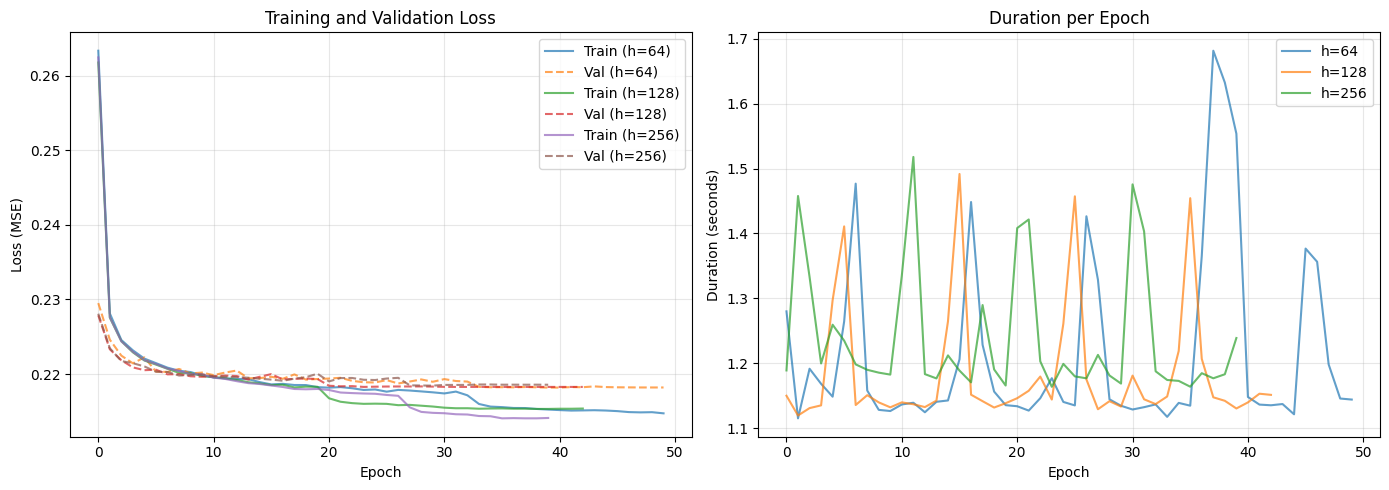

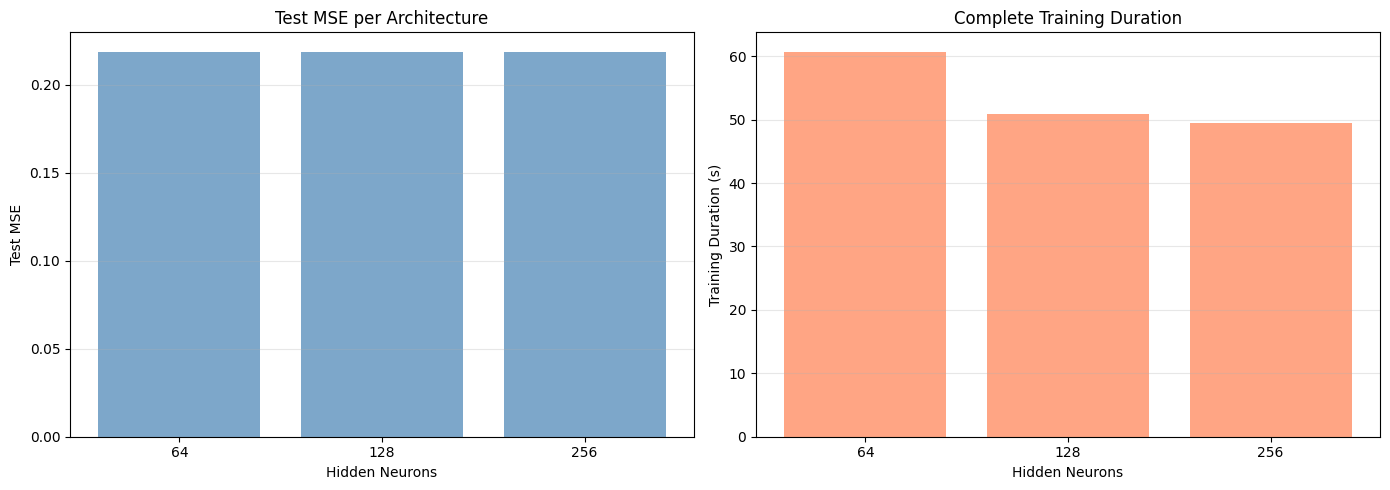


Best model: 128 hidden neurons


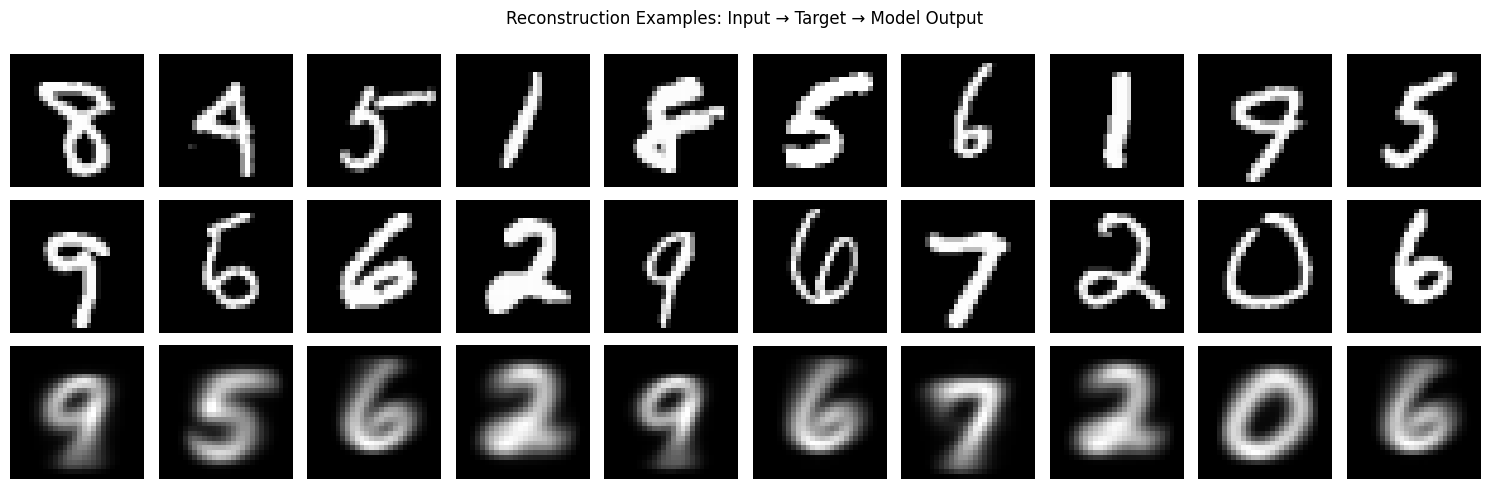


6. Analyzing diagrams for correct and false reconstructions...


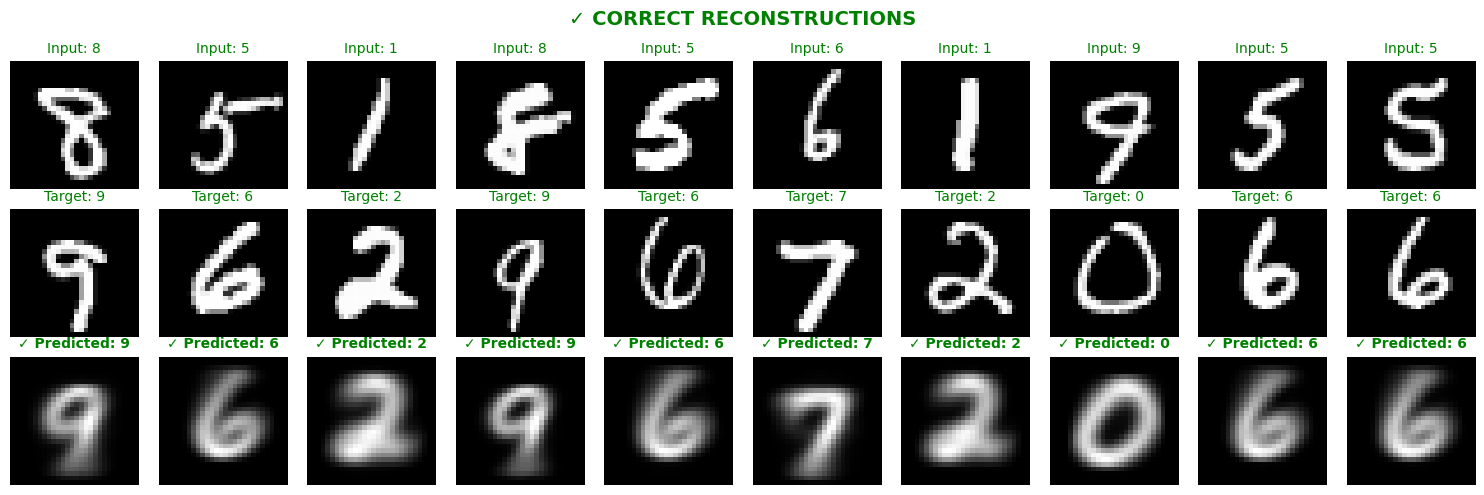

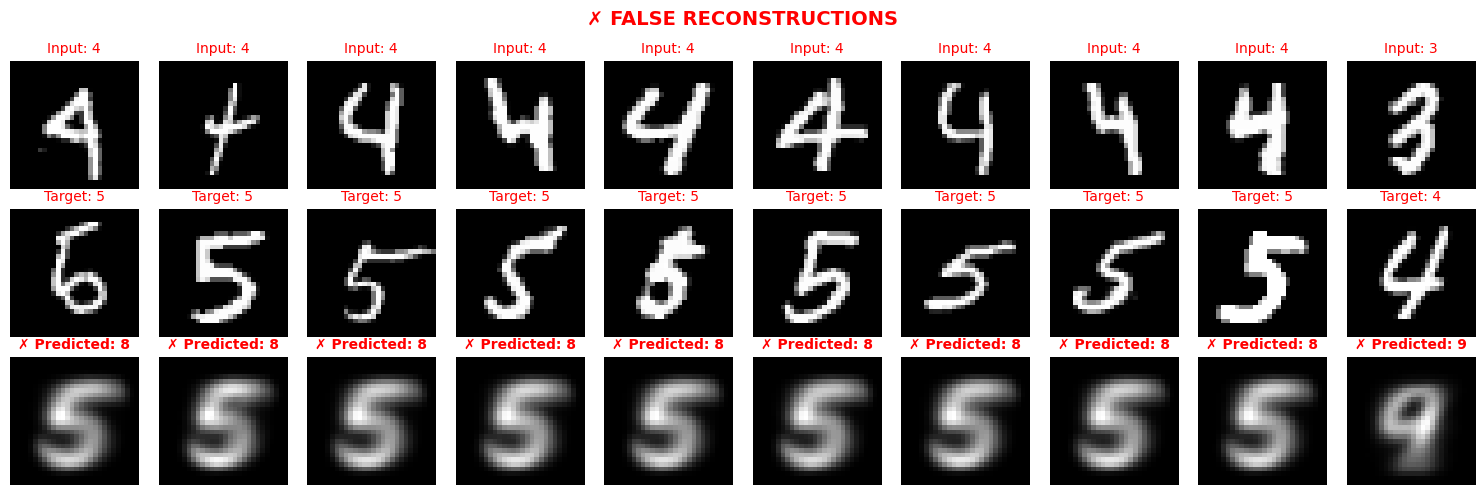


7. Analyzing performance per digit...


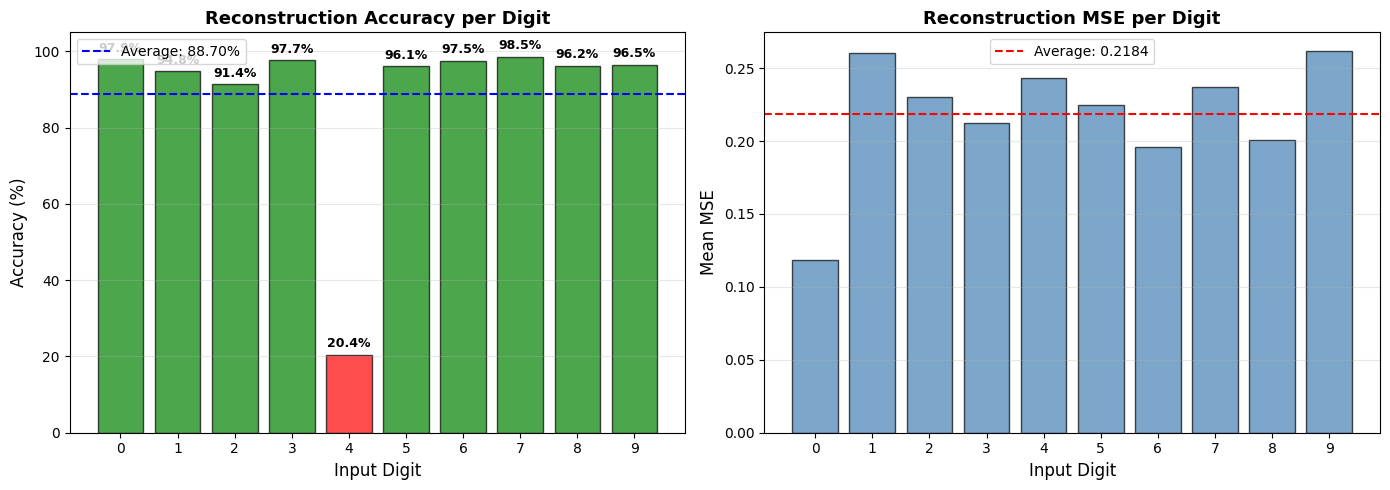


SUMMARIZING RESULTS

Hidden Neurons: 64
    Test MSE: 0.2184
    Classification Accuracy: 90.25%
     Training Time: 60.73s
    Final Train Loss: 0.2147
    Final Val Loss: 0.2182
     Overfitting: ✓ NO (difference: 0.0035)

  Accuracy per input digit:
    0 → 1: 98.8% (1361/1378)
    1 → 2: 95.6% (1407/1472)
    2 → 3: 92.7% (1262/1362)
    3 → 4: 96.8% (1285/1327)
    4 → 5: 30.8% (394/1278)
    5 → 6: 95.8% (1149/1200)
    6 → 7: 97.1% (1358/1398)
    7 → 8: 98.4% (1352/1374)
    8 → 9: 96.6% (1335/1382)
    9 → 0: 96.1% (1328/1382)

Hidden Neurons: 128
    Test MSE: 0.2184
    Classification Accuracy: 89.13%
     Training Time: 50.95s
    Final Train Loss: 0.2154
    Final Val Loss: 0.2183
     Overfitting: ✓ NO (difference: 0.0029)

  Accuracy per input digit:
    0 → 1: 97.9% (1349/1378)
    1 → 2: 94.8% (1395/1472)
    2 → 3: 91.4% (1245/1362)
    3 → 4: 97.7% (1296/1327)
    4 → 5: 20.4% (261/1278)
    5 → 6: 96.1% (1153/1200)
    6 → 7: 97.5% (1363/1398)
    7 → 8: 98.5% (135

In [ ]:
# ===========================================================
# MAIN EXECUTION
# ===========================================================

def main():
    """Main execution function"""
    print("="*70)
    print("AUTOENCODER FOR NEXT DIGIT CREATION USING MNIST")
    print("="*70)

    # Preparing data
    print("\n1. Preparing and loading data...")
    X, Y = prepare_next_digit_data()
    print(f"Dataset: {X.shape[0]} pairs")

    # Split into train (60%), validation(20%) and test (20%)
    train_size = int(0.6 * len(X))
    val_size = int(0.2 * len(X))
    test_size = len(X) - train_size - val_size

    dataset = TensorDataset(X, Y)
    train_dataset, val_dataset, test_dataset = random_split(
        dataset, [train_size, val_size, test_size]
    )

    print(f"Train: {train_size}, Validation: {val_size}, Test: {test_size}")

    # Create DataLoaders
    train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=128)
    test_loader = DataLoader(test_dataset, batch_size=128)

    # Train classifier for evaluation
    print("\n2. Train classifier for evaluation...")
    mnist_train = torchvision.datasets.MNIST(root='./data', train=True,
                                             download=True, transform=transforms.ToTensor())
    mnist_test = torchvision.datasets.MNIST(root='./data', train=False,
                                            download=True, transform=transforms.ToTensor())

    X_mnist = torch.cat([mnist_train.data.float(), mnist_test.data.float()]) / 255.0
    X_mnist = (X_mnist - 0.5) / 0.5
    X_mnist = X_mnist.reshape(-1, 784)
    y_mnist = torch.cat([mnist_train.targets, mnist_test.targets])

    split_idx = int(0.8 * len(X_mnist))
    classifier = train_classifier(X_mnist[:split_idx], y_mnist[:split_idx],
                                 X_mnist[split_idx:], y_mnist[split_idx:])

    # Train for different numbers of hidden neurons
    hidden_dims = [64, 128, 256]
    results = {}
    histories = []

    print("\n3. Train Autoencoders for different architectures...")

    for hidden_dim in hidden_dims:
        print(f"\n--- Train with {hidden_dim} hidden neurons ---")

        model = Autoencoder(hidden_dim=hidden_dim).to(device)

        start_time = time.time()
        history = train_autoencoder(model, train_loader, val_loader, epochs=50, lr=0.001)
        total_time = time.time() - start_time

        histories.append(history)

        # Evaluation
        eval_results = evaluate_reconstruction(model, test_loader, classifier)

        results[hidden_dim] = {
            'model': model,
            'history': history,
            'test_mse': eval_results['mse'],
            'classification_accuracy': eval_results.get('classification_accuracy', 0),
            'total_train_time': total_time,
            'per_digit_stats': eval_results.get('per_digit_stats', {}),
            'correct_examples': eval_results.get('correct_examples', {}),
            'wrong_examples': eval_results.get('wrong_examples', {})
        }

        print(f"Test MSE: {eval_results['mse']:.4f}")
        if 'classification_accuracy' in eval_results:
            print(f"Classification Accuracy: {eval_results['classification_accuracy']:.2f}% "
                  f"({eval_results['total_correct']}/{eval_results['total_samples']})")
        print(f"Total Time: {total_time:.2f}s")

    # Compare with PCA
    print("\n4. Compare with PCA...")
    X_train_full = torch.cat([x for x, _ in train_dataset])
    Y_train_full = torch.cat([y for _, y in train_dataset])
    X_test_full = torch.cat([x for x, _ in test_dataset])
    Y_test_full = torch.cat([y for _, y in test_dataset])

    # Assuring correct dimensions
    if X_train_full.dim() == 1:
        X_train_full = X_train_full.reshape(-1, 784)
    if Y_train_full.dim() == 1:
        Y_train_full = Y_train_full.reshape(-1, 784)
    if X_test_full.dim() == 1:
        X_test_full = X_test_full.reshape(-1, 784)
    if Y_test_full.dim() == 1:
        Y_test_full = Y_test_full.reshape(-1, 784)

    pca_mse, _ = compare_with_pca(X_train_full, Y_train_full,
                                   X_test_full, Y_test_full, n_components=128)
    print(f"PCA Test MSE (128 components): {pca_mse:.4f}")

    # Visualizations
    print("\n5. Creating Visualizations...")
    plot_training_history(histories, hidden_dims)
    plot_comparison_results(results)

    # Showing examples from the best model
    best_hidden_dim = min(results.keys(), key=lambda k: results[k]['test_mse'])
    best_model = results[best_hidden_dim]['model']
    best_results = results[best_hidden_dim]

    print(f"\nBest model: {best_hidden_dim} hidden neurons")

    plot_reconstructions(best_model, X_test_full, Y_test_full, num_examples=10)

    # New diagrams for correct vs false reconstructions
    print("\n6. Analyzing diagrams for correct and false reconstructions...")
    plot_correct_vs_wrong_reconstructions(
        best_results['correct_examples'],
        best_results['wrong_examples']
    )

    # Accuracy per digit
    print("\n7. Analyzing performance per digit...")
    plot_per_digit_accuracy(best_results['per_digit_stats'])

    # Summarizing results
    print("\n" + "="*70)
    print("SUMMARIZING RESULTS")
    print("="*70)

    for hidden_dim in hidden_dims:
        r = results[hidden_dim]
        print(f"\n{'='*70}")
        print(f"Hidden Neurons: {hidden_dim}")
        print(f"{'='*70}")
        print(f"    Test MSE: {r['test_mse']:.4f}")
        print(f"    Classification Accuracy: {r['classification_accuracy']:.2f}%")
        print(f"     Training Time: {r['total_train_time']:.2f}s")
        print(f"    Final Train Loss: {r['history']['train_loss'][-1]:.4f}")
        print(f"    Final Val Loss: {r['history']['val_loss'][-1]:.4f}")

        # Overfitting check
        train_val_diff = abs(r['history']['train_loss'][-1] - r['history']['val_loss'][-1])
        if train_val_diff < 0.01:
            print(f"     Overfitting: ✓ NO (difference: {train_val_diff:.4f})")
        elif train_val_diff < 0.05:
            print(f"     Overfitting:  ~ MEDIUM (difference: {train_val_diff:.4f})")
        else:
            print(f"     Overfitting: ✗ YES (difference: {train_val_diff:.4f})")

        # Statistics per digit
        if r['per_digit_stats']:
            print(f"\n  Accuracy per input digit:")
            for digit in range(10):
                stats = r['per_digit_stats'][digit]
                if stats['total'] > 0:
                    acc = 100 * stats['correct'] / stats['total']
                    print(f"    {digit} → {(digit+1)%10}: {acc:.1f}% ({stats['correct']}/{stats['total']})")

    print(f"\n{'='*70}")
    print(f"PCA (128 components) MSE: {pca_mse:.4f}")
    print(f"{'='*70}")

    # Comparing best model with PCA
    improvement = ((pca_mse - results[best_hidden_dim]['test_mse']) / pca_mse) * 100
    print(f"\n  BEst Model: {best_hidden_dim} Hidden neurons")
    print(f"   Improvement over PCA: {improvement:.2f}%")

    print("\n  Process Complete!")
    print("="*70)

if __name__ == "__main__":
    main()